# Projeto da disciplina de Aprendizado de Máquina
## Criatura Lendária 2 - Tiamat

------

Docente: Daniel Roberto Cassar  
Discente: Maria Clara Costa Ferreira  

## Introdução

A barreira hematoencefálica (BHE) é uma rede capilar altamente seletiva que separa o cérebro do sistema circulatório e impede que substâncias neurotóxicas presentes no sangue atravessem para o fluido extracelular do sistema nervoso central (SNC) [https://www.nature.com/articles/s41597-021-01069-5]. Prever se uma substância atravessa a BHE é muito importante, pois pode ajudar no desenvolvimento de novos fármacos que visam combater doenças do SNC e a identificar compostos em formulações que tem como alvo outras regiões que devem ser evitados, pois podem causar efeitos adversos no cérebro. [https://www.nature.com/articles/s41598-024-66897-y?fromPaywallRec=false]

O conjunto de dados Blood-Brain Barrier Database (B3DB) reúne milhares de descritores moleculares. Estes, por sua vez, são representações matemáticas usadas para descrever quantitativamente as informações físico-químicas das moléculas. Cada descritor leva em consideração uma pequena parte de toda a informação química contida na molécula real, e seu conjunto pode ser usado principalmente para busca de similaridade [https://www.sciencedirect.com/topics/medicine-and-dentistry/molecular-descriptor]. Além disso, o dataset de classificação também conta com um rótulo que informa se a molécula é permeável ou impermeável à BHE.

O objetivo do presente trabalho é, portanto, utilizar esses descritores para prever se substâncias atravessam ou não a barreira hematoencefálica.

## Bibliotecas

Para o desenvolvimento desse código foram utilizadas as seguintes bibliotecas:

In [1]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score 
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
from optuna import create_study
from functools import partial
from rdkit import Chem
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
import optuna


optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings(
    "ignore",
    message = "Skipping features without any observed values",
    category = UserWarning,
)

****************************

## Análise exploratória dos dados

Inicialmente, é criado um dataframe a partir do dataset em formato de arquivo TSV. O dataframe, então, é exibido para uma visão geral de suas colunas e linhas.

In [2]:
# load extended classification dataset
df_classificacao = pd.read_csv("classification_extended_test.tsv", sep="\t")
df_classificacao

C:\Users\maria2610071\AppData\Local\Temp\ipykernel_25216\3210880104.py:2: DtypeWarning: Columns (0: comments) have mixed types. Specify dtype option on import or set low_memory=False.
  df_classificacao = pd.read_csv("classification_extended_test.tsv", sep="\t")


,NO.,compound_name,IUPAC_name,SMILES,CID,logBB,BBB+/BBB-,Inchi,threshold,reference,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,1,sulphasalazine,2-hydroxy-5-[[4-(pyridin-2-ylsulfamoyl)phenyl]...,O=C(O)c1cc(N=Nc2ccc(S(=O)(=O)Nc3ccccn3)cc2)ccc1O,5339.0,-2.69,BBB-,InChI=1S/C18H14N4O5S/c23-16-9-6-13(11-15(16)18...,NaN,R2|R2|R25|R46|,...,10.171643,63.201012,398.068491,9.477821,2428,42,144,165,9.590278,6.097222
1,2,moxalactam,7-[[2-carboxy-2-(4-hydroxyphenyl)acetyl]amino]...,COC1(NC(=O)C(C(=O)O)c2ccc(O)cc2)C(=O)N2C(C(=O)...,3889.0,-2.52,BBB-,InChI=1S/C20H20N6O9S/c1-25-19(22-23-24-25)36-8...,NaN,R25|,...,10.893010,87.033695,520.101247,9.287522,4114,62,194,237,13.756944,7.916667
2,3,clioquinol,5-chloro-7-iodoquinolin-8-ol,Oc1c(I)cc(Cl)c2cccnc12,2788.0,-2.40,BBB-,InChI=1S/C9H5ClINO/c10-6-4-7(11)9(13)8-5(6)2-1...,NaN,R18|R26|R27|,...,9.618402,44.825548,304.910439,16.939469,218,21,68,81,4.805556,2.861111
3,4,bbcpd11 (cimetidine analog) (y-g13),2-[2-[(3-bromopyridin-2-yl)methylsulfanyl]ethy...,CCNC(=NCCSCc1ncccc1Br)NC#N,14022517.0,-2.15,BBB-,InChI=1S/C12H16BrN5S/c1-2-15-12(18-9-14)17-6-7...,NaN,R2|R2|R8|R40|R2|R2|R2|R2|R18|R21|R25|R25|R26|R...,...,9.201199,50.610337,341.030979,9.743742,898,22,82,88,6.583333,4.694444
4,5,schembl614298,"(2s,3s,4s,5r)-6-[[(4r,4ar,7s,7ar,12bs)-7-hydro...",CN1CC[C@]23c4c5ccc(OC6O[C@H](C(=O)O)[C@@H](O)[...,18595497.0,-2.15,BBB-,InChI=1S/C23H27NO9/c1-24-7-6-23-10-3-4-12(25)2...,NaN,R25|,...,10.992336,85.350582,461.168581,7.686143,2850,74,198,254,11.229167,6.847222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7802,7803,antazoline,"n-benzyl-n-(4,5-dihydro-1h-imidazol-2-ylmethyl...",c1ccc(CN(CC2=NCCN2)c2ccccc2)cc1,2200.0,NaN,BBB-,InChI=1S/C17H19N3/c1-3-7-15(8-4-1)13-20(14-17-...,NaN,R14|R23|R50|,...,9.582249,66.060685,265.157898,6.798920,829,24,100,113,4.444444,4.527778
7803,7804,emedastine,"1-(2-ethoxyethyl)-2-(4-methyl-1,4-diazepan-1-y...",CCOCCn1c(N2CCCN(C)CC2)nc2ccccc21,3219.0,NaN,BBB+,InChI=1S/C17H26N4O/c1-3-22-14-13-21-16-8-5-4-7...,NaN,R15|R23|R50|,...,9.863134,70.340391,302.210661,6.296055,1041,35,112,131,6.166667,5.027778
7804,7805,ketotifen,2-(1-methylpiperidin-4-ylidene)-6-thiatricyclo...,CN1CCC(=C2c3ccccc3CC(=O)c3sccc32)CC1,3827.0,NaN,BBB+,InChI=1S/C19H19NOS/c1-20-9-6-13(7-10-20)18-15-...,NaN,R15|R27|R50|,...,10.124268,70.590222,309.118735,7.539481,917,40,122,148,5.888889,4.750000
7805,7806,milrinone,6-methyl-2-oxo-5-pyridin-4-yl-1h-pyridine-3-ca...,Cc1[nH]c(=O)c(C#N)cc1-c1ccncc1,4197.0,NaN,BBB-,InChI=1S/C12H9N3O/c1-8-11(9-2-4-14-5-3-9)6-10(...,NaN,R15|R23|R27|,...,9.618801,48.335122,211.074562,8.442982,425,24,80,93,5.555556,3.666667


In [3]:
n_moleculas = df_classificacao.shape[0]
n_colunas = df_classificacao.shape[1]
print(f"O número de moléculas nesse dataset é {n_moleculas}.")
print(f"Enquanto isso, existem {n_colunas} colunas nesse dataset.")

O número de moléculas nesse dataset é 7807.
Enquanto isso, existem 1625 colunas nesse dataset.


Em seguida, observamos as colunas do dataset. Elas são compostas por inúmeros identificadores oficiais, SMILES (notação textual que representa a estrutura química de uma molécula), o valor em logaritmo para a razão entre a concentração da molécula no cérebro e sua concentração no sangue, o rótulo binário que separa se atravessa ou não a BHE e, em sua grande maioria, o restante é composto por descritores moleculares.

In [4]:
df_classificacao.columns

Index(['NO.', 'compound_name', 'IUPAC_name', 'SMILES', 'CID', 'logBB',
       'BBB+/BBB-', 'Inchi', 'threshold', 'reference',
       ...
       'SRW10', 'TSRW10', 'MW', 'AMW', 'WPath', 'WPol', 'Zagreb1', 'Zagreb2',
       'mZagreb1', 'mZagreb2'],
      dtype='str', length=1625)

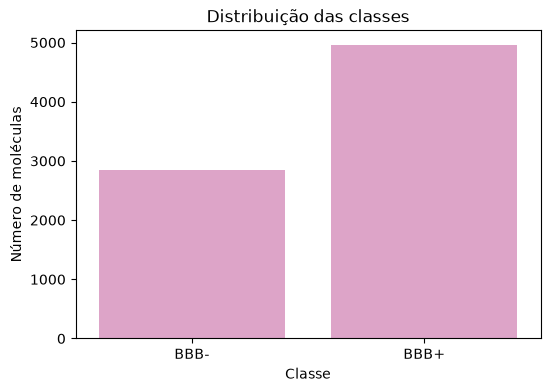

In [5]:
TARGET = "BBB+/BBB-"

plt.figure(figsize = (6 ,4))
sns.countplot(data = df_classificacao, x = TARGET, color = "#E69BCB")
plt.title("Distribuição das classes")
plt.xlabel("Classe")
plt.ylabel("Número de moléculas")
plt.show()

In [6]:
print(f"Existem {df_classificacao.isna().all().sum()} atributos completamente vazios.")

Existem 76 atributos completamente vazios.


In [7]:
identificadores = ["NO.", "compound_name", "IUPAC_name", "CID", "logBB",
        "Inchi", "threshold", "reference", "group", "comments"]

#Criando dataframe para modelagem
df_modelagem = df_classificacao.drop(columns = identificadores).copy()
colunas_vazias = df_modelagem.columns[df_modelagem.isna().all()]
df_modelagem = df_modelagem.drop(columns = colunas_vazias)

#Separa os dados
ATRIBUTOS = df_modelagem.drop(columns = ["BBB+/BBB-", "SMILES"])
TARGET = df_modelagem["BBB+/BBB-"]
SMILES = df_modelagem["SMILES"].copy()

In [8]:
# Define-se a quantidade de ausentes por atributo
ausentes = ATRIBUTOS.isna().sum()
porcentagem_ausentes = ATRIBUTOS.isna().mean() * 100

print(f"""
    Atributos com valores ausentes: {(ausentes > 0).sum()}
    O total de valores ausentes é: {ausentes.sum()}.
    """)


    Atributos com valores ausentes: 804
    O total de valores ausentes é: 604601.
    


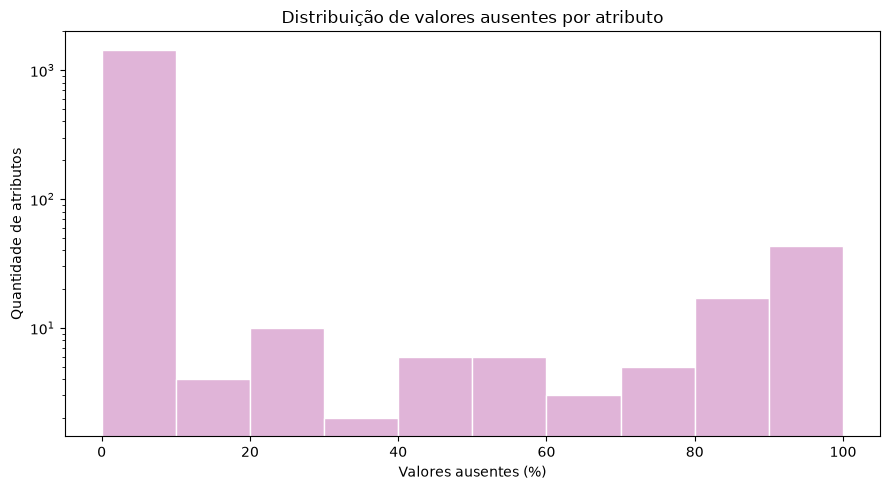

In [9]:
plt.figure(figsize=(9,5))

sns.histplot(
    porcentagem_ausentes,
    bins=10,
    edgecolor="white",
    color = "#D69BCB"
)

plt.xlabel("Valores ausentes (%)")
plt.ylabel("Quantidade de atributos")
plt.yscale("log")
plt.title("Distribuição de valores ausentes por atributo")
plt.tight_layout()
plt.show()

## Separação de treino e teste – (MurckoScaffold)

In [10]:
# Aqui se usa MurckoScaffold

SEMENTE_ALEATORIA = 1912

def scaffold(smiles):
    
    mol = Chem.MolFromSmiles(smiles)
    
    if mol is None:
        return None
        
    sc = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    
# Sem anel -> Scaffold vazio e usa o próprio SMILES
    if sc != "":
        return sc
    else:
        return smiles

# Calcula Scaffolds
df_modelagem["scaffold"] = df_modelagem["SMILES"].apply(scaffold)

# Remove SMILES inválidos
df_modelagem = df_modelagem.dropna(subset=["scaffold"]).copy()
grupos = df_modelagem["scaffold"].astype("category").cat.codes


[22:33:47] Explicit valence for atom # 10 C, 4, is greater than permitted
[22:33:50] Explicit valence for atom # 10 C, 4, is greater than permitted


In [11]:
# Aqui se usa GroupShuffleSplit
# Divisão em treino e teste baseada em scaffolds

gss = GroupShuffleSplit(
    n_splits = 1,
    test_size = 0.1,
    random_state = SEMENTE_ALEATORIA
)

indices_treino, indices_teste = next(
    gss.split(
        df_modelagem[ATRIBUTOS.columns],
        df_modelagem[TARGET.name],
        groups = grupos
    )
)

df_treino = df_modelagem.iloc[indices_treino]
df_teste = df_modelagem.iloc[indices_teste]

X_treino, y_treino = df_treino[ATRIBUTOS.columns], df_treino[TARGET.name]
X_teste, y_teste = df_teste[ATRIBUTOS.columns], df_teste[TARGET.name]

In [12]:
NUM_FOLDS = 10

grupos_treino = df_treino["scaffold"]
cv = StratifiedGroupKFold(n_splits = NUM_FOLDS, shuffle = True, random_state = SEMENTE_ALEATORIA)

## Modelo Baseline

In [13]:
# Aqui se usa DummyClassifier

modelo_baseline = DummyClassifier()
modelo_baseline.fit(X_treino, y_treino)

DummyClassifier()

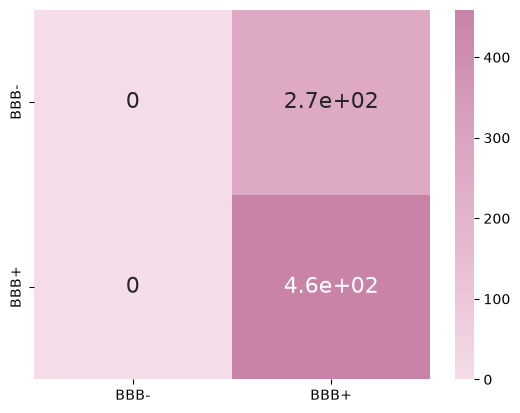

In [14]:
# Aqui se usa confusion_matrix
ordem_labels = df_modelagem["BBB+/BBB-"].unique().tolist()

y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao, labels=ordem_labels)
df_conf = pd.DataFrame(matriz_conf, ordem_labels, ordem_labels)

# Aquis se usa LinearSegmentedColormap

paleta = LinearSegmentedColormap.from_list(
    "soft_scientific",
    [ "#F4DCE8",
    "#E8BBD0",
    "#D9A3C1",
    "#C982A8",]
)

sns.heatmap(df_conf, annot=True, annot_kws={"size": 16}, cmap = paleta);

In [15]:
# Aqui se usa accuracy_score

acuracia = accuracy_score(y_verdadeiro, y_previsao)

print(f"Acurácia = {(acuracia*100):.2f}%")

Acurácia = 63.22%


In [16]:
X = X_treino.to_numpy(dtype=float)
print("NaNs:", np.isnan(X).sum())

NaNs: 549450


## K-Nearest Neighbors

### Modelo e espaço de busca

In [23]:
def cria_selecao(trial):
    return SelectKBest(score_func = f_classif,
                       k = trial.suggest_int("k", 20, 500))

In [24]:
def cria_instancia_knn(trial):
    """Cria uma instância do modelo.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    parametros = {
        # espaço de busca
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 200, log = True),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan"]),
        # argumentos fixos
        "n_jobs": -2,
    }
         
    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        StandardScaler(),
        KNeighborsClassifier(**parametros)
    )

    return modelo

In [25]:
def funcao_objetivo(trial, X, y):
    """Função objetivo do optuna

    Referencia:
      https://medium.com/@walter_sperat/ using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451
    """

    modelo = cria_instancia_knn(trial)

    metricas = cross_val_score(
        modelo,
        X,
        y,
        scoring="roc_auc",
        cv=cv,
        groups = grupos_treino,
        n_jobs = -2,
    )

    return metricas.mean()

In [26]:
NOME_DO_ESTUDO = "knn_3b"

objeto_de_estudo = create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
)

In [27]:
funcao_objetivo_parcial = partial(
    funcao_objetivo, X=X_treino, y=y_treino
)

In [ ]:
NUM_TENTATIVAS = 100

objeto_de_estudo.optimize(funcao_objetivo_parcial, n_trials=NUM_TENTATIVAS)

In [29]:
df_resultado_knn = objeto_de_estudo.trials_dataframe()

df_resultado_knn

,number,value,datetime_start,datetime_complete,duration,params_k,params_metric,params_n_neighbors,params_weights,state
0,0,0.878341,2026-11-17 22:34:55.544606,2026-11-17 22:35:19.147200,0 days 00:00:23.602594,465,euclidean,161,distance,COMPLETE


## Árvore de Decisão

In [ ]:
def cria_instancia_arvore(trial):
    """Cria uma instância do modelo de árvore de decisão.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
    
    parametros = {
        # espaço de busca
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]), #critério de split
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 200, log = True),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-5, 1e-2, log=True),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        DecisionTreeClassifier(**parametros)
    )

    return modelo

## Floresta Aleatória

In [ ]:
def cria_instancia_floresta(trial):
    """Cria uma instância do modelo de floresta aleatória.

    Args:
      trial: objeto tipo Trial do optuna.

    Returns:
      Uma instância do modelo desejado.
    """
     k = trial.suggest_int("k", 15, 500)

    selecao = SelectKBest(score_func = f_regression, k = k)

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("n_estimators", 50, 1000, log=True),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy"]), #critério de split
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

     modelo = make_pipeline(
        SimpleImputer(strategy = "median"),
        VarianceThreshold(),
        cria_selecao(trial),
        DecisionTreeClassifier(**parametros)
    )

    return modelo

## Apêndice I - Nota sobre a abordagem de classificação

A proposta inicial desse trabalho era desenvolver modelos de regressão para prever os valores quantitativos de permeabilidade na barreira hematoencefálica (logBB), utilizando o dataset "B3DB_regression_extended.tsv.gz", do banco Blood-Brain Barrier Dataset (B3DB).

No entanto, já no primeiro modelo o RMSE obtido foi de 0,7 unidades de logBB. Isso significa que o modelo errava na razão entre as concentrações cerebrais e sanguíneas por um fator de 5 vezes (já que $10^{0,7}\approx 5\$). O volume de dados do dataset de regressão era um tanto limitado, com pouco mais de 1000 compostos, o que dificulta o aprendizado de relações mais complexas, e havia vazamento de dados no código, cuja estrutura se emaranhava sem direção. O dataset foi trocado pelo de classificação e o trabalho reiniciadomotivo pelo qual a versão inicial do arquivo não corresponde às versões finais.


https://medium.com/data-hackers/como-selecionar-as-melhores-features-para-seu-modelo-de-machine-learning-faf74e357913

https://www.nature.com/articles/s41597-021-01069-5

https://www.nature.com/articles/s41598-024-66897-y?fromPaywallRec=false

https://www.sciencedirect.com/topics/medicine-and-dentistry/molecular-descriptor